<a href="https://colab.research.google.com/github/jlnsmith2001/450DataScienceDevWinter2026LectureCode/blob/main/neural_network_fashion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Deep Learning Project 1
### Image Classification with nueral nets using clothing images
### Julien Smith

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jlnsmith2001/repo/blob/main/path-to-file)
**Note:** Replace `username`, `repo`, and `path-to-file` above with your own GitHub username, repository name, and the exact path to this file in your repo.

In [ ]:
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
keras.utils.set_random_seed(42)

### Data loading and preprocessing

First, I needed to load in the data and allocate data as both train and testing data. Then, I needed to normalize the pixel values from (0, 255) to (0, 1) to standardize it so the model can be trained on a range of values that are consistent and can learn more easily on how to update weights during backpropagation. Lastly, I needed to flatten the input layer from a 2d representation of 28x28 to a 1d array of 784 elements to be able to be fed into the model

In [ ]:
(X_train, y_train), (X_test, y_test) = keras.datasets.fashion_mnist.load_data()

X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

X_train = X_train.reshape((X_train.shape[0], 784))
X_test = X_test.reshape((X_test.shape[0], 784))


29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


### Exploration and visualization

First, I wanted to create a visualization to retrieve a sample of each clothing item  within the  fashion dataset, consisting of images of things like jackets, shoes, and shirts. I accomplished this by using np.unqiue to retrieve the label associated with each class.

I then created a countplot of both y_train and y_test, noting that the distribution of each class was the exact same meaning that there wont be a single class that is necessarily over represented in the data.


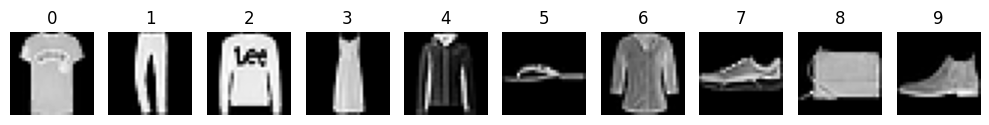

In [ ]:

unique_classes, indices = np.unique(y_test, return_index = True)
selected_classes = y_test[indices]
selected_data =  X_test[indices]

fig = plt.figure(figsize=(10,2))
for i in range(10):
    plt.subplot(1, 10, i+1)
    number_image = selected_data[i]
    plt.imshow(number_image.reshape(28, 28), cmap = "grey")
    plt.title(selected_classes[i])
    plt.axis("off")
plt.tight_layout()


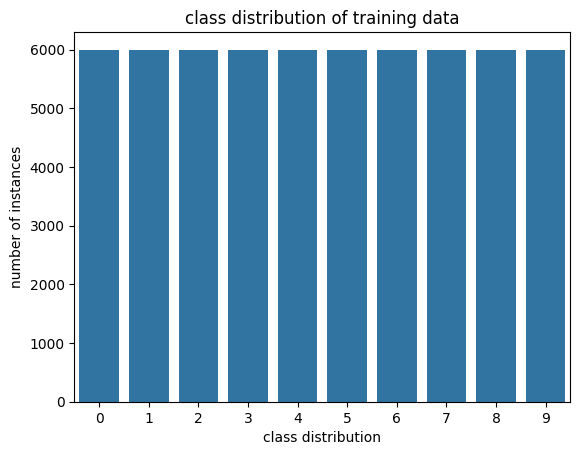

In [ ]:
sns.countplot(x = y_train)
plt.xlabel("class distribution")
plt.ylabel("number of instances")
plt.title("class distribution of training data")
plt.show()

In [ ]:
y_train_tra = pd.Series(data = y_train, index = None, dtype = None, name = None)
y_train_counts = y_train_tra.value_counts()

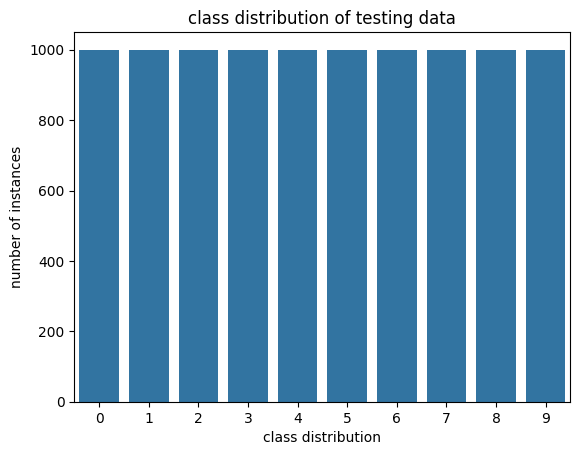

In [ ]:
sns.countplot(x=y_test)
plt.xlabel("class distribution")
plt.ylabel("number of instances")
plt.title("class distribution of testing data")
plt.show()

In [ ]:
y_test_tes = pd.Series(data = y_test, index = None, dtype = None, name = None)
y_test_counts = y_test_tes.value_counts()

In [ ]:
value_count = {
    "y_train_counts": y_train_counts,
    "y_test_counts": y_test_counts
}

value_counts_df = pd.DataFrame(value_count)
value_counts_df

,y_train_counts,y_test_counts
0,6000,1000
1,6000,1000
2,6000,1000
3,6000,1000
4,6000,1000
5,6000,1000
6,6000,1000
7,6000,1000
8,6000,1000
9,6000,1000


### Model Implementation

For Model Implementation, I decided to seperate shallow models from deep models into their respective sections. For each shallow model I ensured that the architecture was consistent, using 2 dense layers with 64 neurons and one output layer using the softmax function. This way, we can contrast results across all models using the same controlled comparison.

I then compiled each model, using the adam optimizer, tracking loss with sparse cross categorical entropy, and specifying  for accuracy.

I seperated each model architecture (shallow vs deep) into two seperate dictionaries, in order to not have to repeatedly call model.fit and instead utilizing a for loop, before  fitting it against the predicted labels and the true labels. Each model was fit using a validation split of 0.2, 50 epochs, and a parameter that specified early stopping at 3 epochs if validation loss were to plateau for 3 consecutive iterations.

In [ ]:
shallow_relu = keras.Sequential([
    layers.Input(shape=(784,)),
    layers.Dense(64, activation = "relu"),
    layers.Dense(64, activation = "relu"),
    layers.Dense(10, activation = "softmax")
])

shallow_sigmoid = keras.Sequential([
    layers.Input(shape=(784,)),
    layers.Dense(64, activation = "sigmoid"),
    layers.Dense(64, activation = "sigmoid"),
    layers.Dense(10, activation = "softmax")
])

shallow_tanh = keras.Sequential([
    layers.Input(shape =(784,)),
    layers.Dense(64, activation = "tanh"),
    layers.Dense(64, activation = "tanh"),
    layers.Dense(10, activation = "softmax")
])

shallow_relu.compile(
    optimizer = keras.optimizers.Adam(1e-3),
    loss = "sparse_categorical_crossentropy",
    metrics = ["accuracy"]
)

shallow_sigmoid.compile(
    optimizer = keras.optimizers.Adam(1e-3),
    loss = "sparse_categorical_crossentropy",
    metrics =["accuracy"]
)

shallow_tanh.compile(
    optimizer = keras.optimizers.Adam(1e-3),
    loss = "sparse_categorical_crossentropy",
    metrics = ["accuracy"]
)

For deep models, each model was instantiated with 4 hidden layers consisting of 256 neurons, although they were similarly compiled using adam as the optimizer, sparse categorical cross entropy as the loss, and prioritizing accuracy.

In [ ]:
deep_relu = keras.Sequential([
    layers.Input(shape=(784, )),
    layers.Dense(256, activation = "relu"),
    layers.Dense(256, activation = "relu"),
    layers.Dense(256, activation = "relu"),
    layers.Dense(256, activation = "relu"),
    layers.Dense(10, activation = "softmax")
])

deep_relu.compile(
    optimizer = keras.optimizers.Adam(1e-3),
    loss = "sparse_categorical_crossentropy",
    metrics = ["accuracy"]
)

deep_sigmoid = keras.Sequential([
    layers.Input(shape=(784, )),
    layers.Dense(256, activation = "sigmoid"),
    layers.Dense(256, activation = "sigmoid"),
    layers.Dense(256, activation = "sigmoid"),
    layers.Dense(256, activation = "sigmoid"),
    layers.Dense(10, activation = "softmax")
])

deep_sigmoid.compile(
    optimizer = keras.optimizers.Adam(1e-3),
    loss = "sparse_categorical_crossentropy",
    metrics = ["accuracy"]
)

deep_tanh = keras.Sequential([
    layers.Input(shape=(784, )),
    layers.Dense(256, activation = "tanh"),
    layers.Dense(256, activation = "tanh"),
    layers.Dense(256, activation = "tanh"),
    layers.Dense(256, activation = "tanh"),
    layers.Dense(10, activation = "softmax")
])

deep_tanh.compile(
    optimizer = keras.optimizers.Adam(1e-3),
    loss = "sparse_categorical_crossentropy",
    metrics = ["accuracy"]
)

In [ ]:
shallow_models= {
    "shallow_relu": shallow_relu,
    "shallow_tanh": shallow_tanh,
    "shallow_sigmoid": shallow_sigmoid,
}

shallow_histories = {
}

for name, model in shallow_models.items():
    history = model.fit(X_train, y_train, validation_split = 0.2, epochs = 50, callbacks = [EarlyStopping(monitor = "val_loss", patience = 3, restore_best_weights = True)])
    shallow_histories[name] = history


Epoch 1/50
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.8110 - loss: 0.5362 - val_accuracy: 0.8509 - val_loss: 0.4187
Epoch 2/50
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8593 - loss: 0.3898 - val_accuracy: 0.8626 - val_loss: 0.3798
Epoch 3/50
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.8710 - loss: 0.3515 - val_accuracy: 0.8698 - val_loss: 0.3588
Epoch 4/50
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.8803 - loss: 0.3256 - val_accuracy: 0.8703 - val_loss: 0.3511
Epoch 5/50
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.8863 - loss: 0.3079 - val_accuracy: 0.8767 - val_loss: 0.3416
Epoch 6/50
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.8916 - loss: 0.2944 - val_accuracy: 0.8762 - val_loss: 0.3438
Epoch 7/50
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8956 - loss: 0.2808 - val_accuracy: 0.8772 - val_loss: 0.3491
Epoch 8/50
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.9007 - loss: 0.2683 -

In [ ]:
    deep_models = {
    "deep_relu": deep_relu,
    "deep_tanh": deep_tanh,
    "deep_sigmoid": deep_sigmoid
    }

    deep_histories = {
    }

    for name, model in deep_models.items():
      history = model.fit(X_train, y_train, validation_split = 0.2, epochs = 50, callbacks = [EarlyStopping(monitor = "val_loss", patience = 3, restore_best_weights = True)])
      deep_histories[name] = history

Epoch 1/50
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 18s 11ms/step - accuracy: 0.8126 - loss: 0.5141 - val_accuracy: 0.8489 - val_loss: 0.4278
Epoch 2/50
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 17s 11ms/step - accuracy: 0.8576 - loss: 0.3846 - val_accuracy: 0.8651 - val_loss: 0.3878
Epoch 3/50
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 16s 11ms/step - accuracy: 0.8721 - loss: 0.3435 - val_accuracy: 0.8683 - val_loss: 0.3645
Epoch 4/50
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 16s 11ms/step - accuracy: 0.8805 - loss: 0.3204 - val_accuracy: 0.8737 - val_loss: 0.3478
Epoch 5/50
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 16s 10ms/step - accuracy: 0.8898 - loss: 0.2975 - val_accuracy: 0.8727 - val_loss: 0.3599
Epoch 6/50
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 16s 11ms/step - accuracy: 0.8949 - loss: 0.2803 - val_accuracy: 0.8783 - val_loss: 0.3603
Epoch 7/50
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 17s 11ms/step - accuracy: 0.8980 - loss: 0.2669 - val_accuracy: 0.8814 - val_loss: 0.3505
Epoch 1/50
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 18s 11ms/step - accuracy: 0.8112 -

# Shallow Models
Loss and accuracy curves for the shallow models

First, I wanted to plot both the loss and accuracy curves for the shallow models. For each respective graph training data was represented by a green line, and validation data was represented with red. One  consistent pattern across all 3 models regarding training and validation loss was that training loss decreased sharply within the first few epochs, whereas validation loss fell more gradually and slightly increased near the end of the training for models such as shallow relu and shallow tanh.

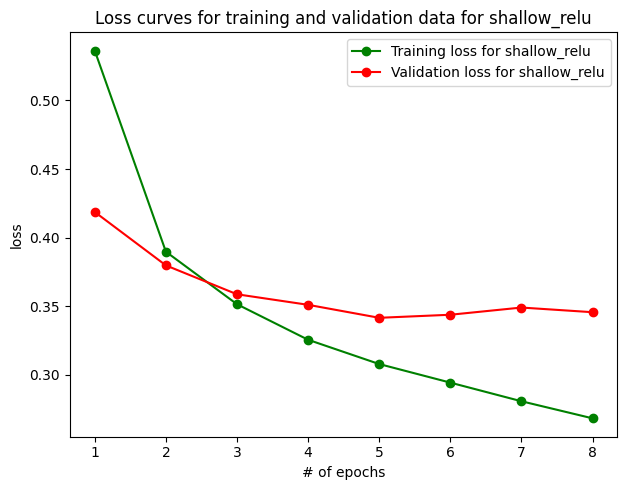

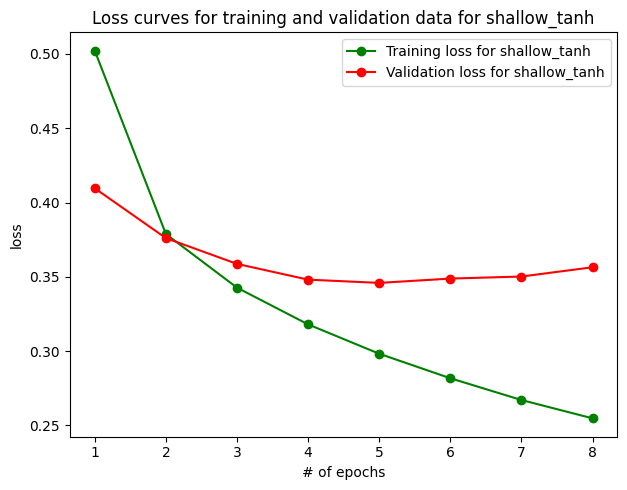

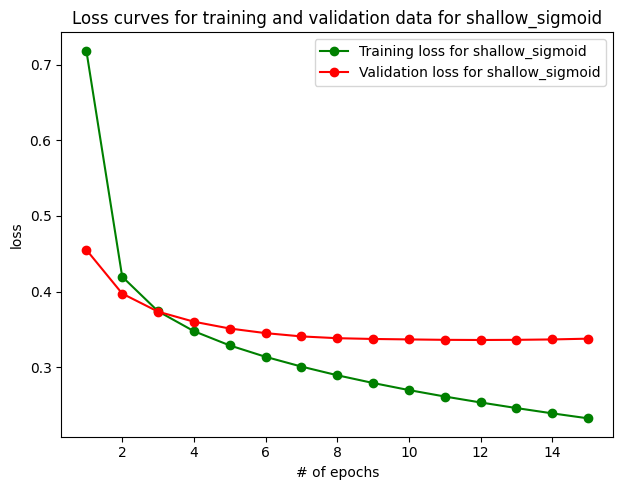

In [ ]:
for model, history in shallow_histories.items():
  training_loss = history.history["loss"]
  validation_loss = history.history["val_loss"]
  epochs = range(1, len(training_loss) + 1)

  plt.figure(figsize = (12, 5))
  plt.subplot(1, 2, 1)
  plt.plot(epochs, training_loss, "go-", label = f"Training loss for {model}")
  plt.plot(epochs, validation_loss, "ro-", label = f"Validation loss for {model}")
  plt.title(f"Loss curves for training and validation data for {model}")
  plt.xlabel("# of epochs")
  plt.ylabel("loss")
  plt.legend()

  plt.tight_layout()
  plt.show()

Looking at the accuracy curves regarding the training and validation data for shallow models, validation accuracy seems relatively stable all throughout training for shallow sigmoid.

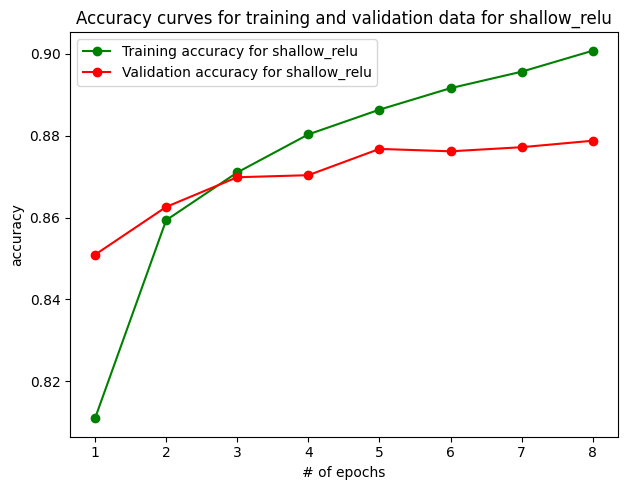

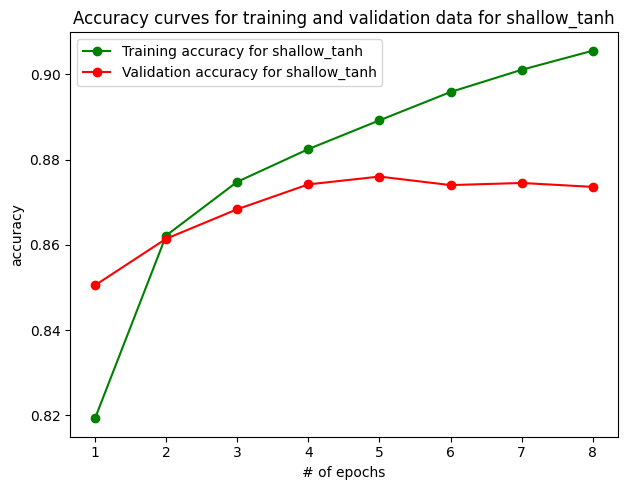

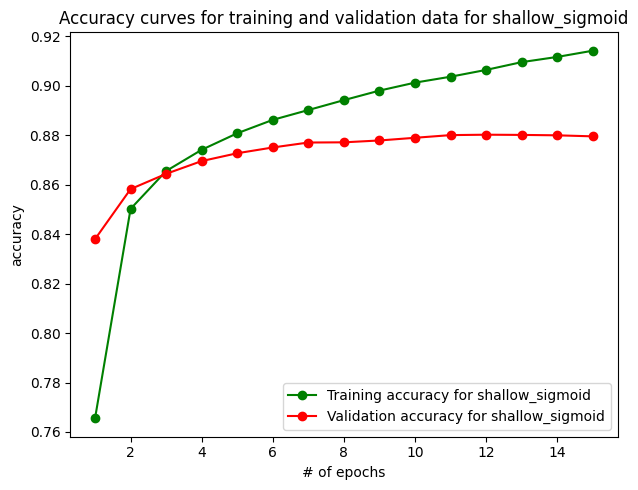

In [ ]:
for model, history in shallow_histories.items():
  training_accuracy = history.history["accuracy"]
  validation_accuracy = history.history["val_accuracy"]
  epochs = range(1, len(training_accuracy) + 1)

  plt.figure(figsize = (12, 5))
  plt.subplot(1, 2, 1)
  plt.plot(epochs, training_accuracy, "go-", label = f"Training accuracy for {model}")
  plt.plot(epochs, validation_accuracy, "ro-", label = f"Validation accuracy for {model}")
  plt.title(f"Accuracy curves for training and validation data for {model}")
  plt.xlabel("# of epochs")
  plt.ylabel("accuracy")
  plt.legend()

  plt.tight_layout()
  plt.show()

# Shallow models
Classification reports and confusion matrices  for shallow models

Each shallow model seemed to do relatively well when identifying classes 7, 8, and 9, although shallow relu and shallow tanh  seemed to struggle with classes 0, 2, and 6.
shallow sigmoid also struggled with class 6, although seemed to do slightly better in identifying classes 0 and 2

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step




classification report for shallow_relu
              precision    recall  f1-score   support

           0     0.8629    0.7680    0.8127      1000
           1     0.9927    0.9550    0.9735      1000
           2     0.7753    0.7660    0.7706      1000
           3     0.8125    0.9230    0.8642      1000
           4     0.7906    0.7890    0.7898      1000
           5     0.9683    0.9460    0.9570      1000
           6     0.6710    0.6750    0.6730      1000
           7     0.8869    0.9720    0.9275      1000
           8     0.9518    0.9680    0.9598      1000
           9     0.9774    0.9090    0.9420      1000

    accuracy                         0.8671     10000
   macro avg     0.8689    0.8671    0.8670     10000
weighted avg     0.8689    0.8671    0.8670     10000

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step




classification report for shallow_tanh
              precision    recall  f1-score   support

           0     0

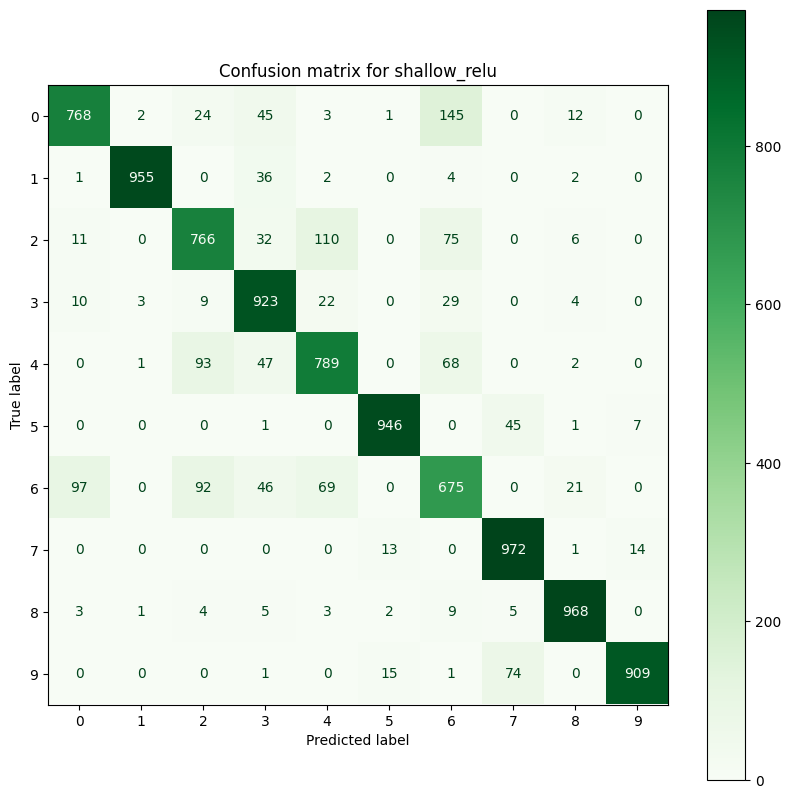

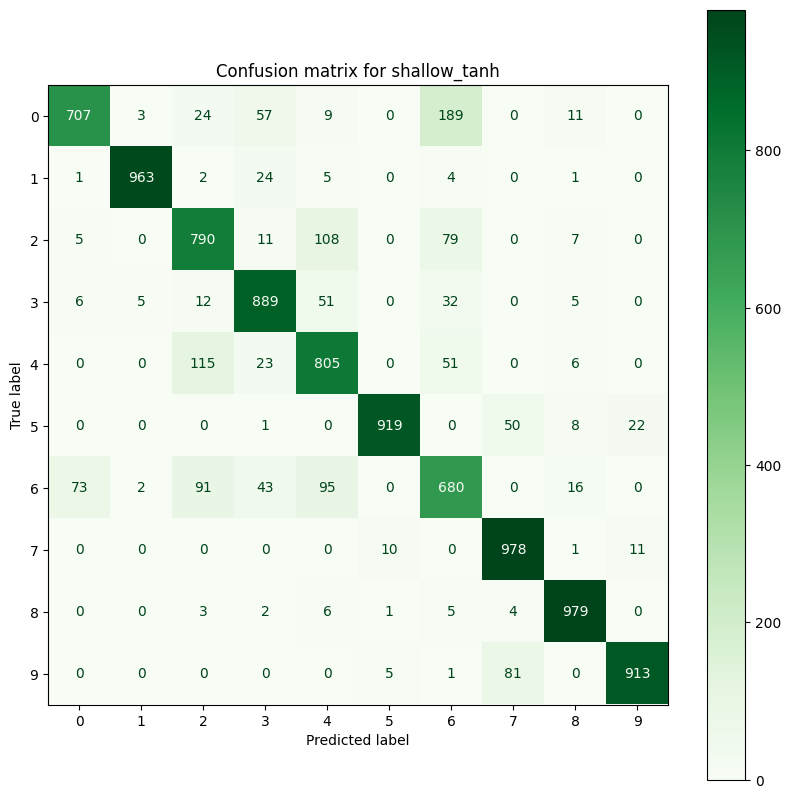

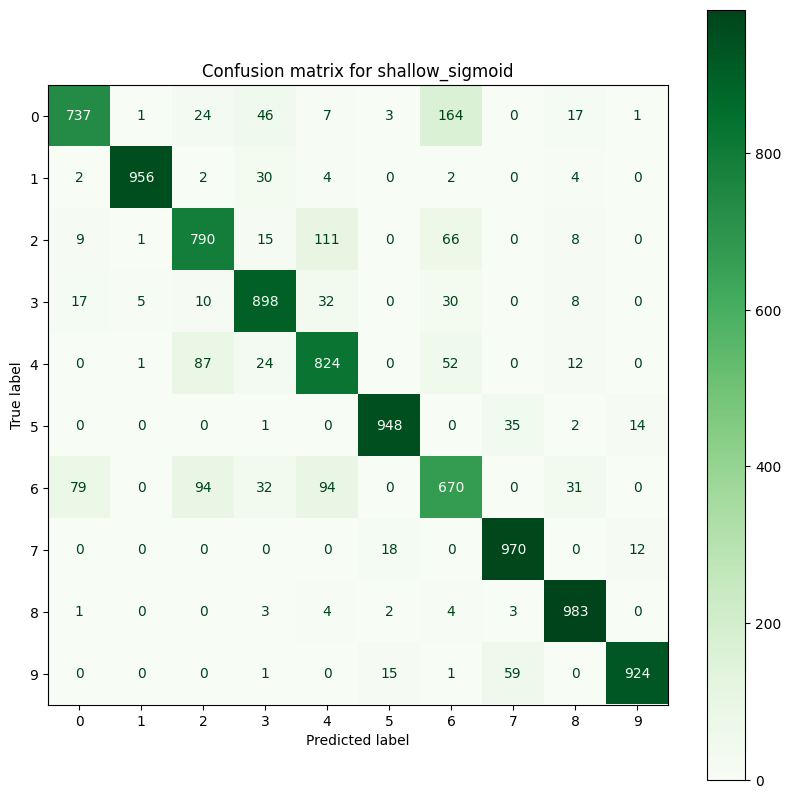

In [ ]:
for name, model in shallow_models.items():
  y_pred = model.predict(X_test)
  y_pred_classes = np.argmax(y_pred, axis = 1)

  conf_matrix = confusion_matrix(y_test, y_pred_classes)
  fig, ax = plt.subplots(figsize = (10, 10))
  display = ConfusionMatrixDisplay(confusion_matrix = conf_matrix, display_labels = range(10))
  display.plot(ax = ax, values_format = "d", cmap=plt.cm.Greens)
  plt.title(f"Confusion matrix for {name}")
  print("\n")
  print("\n")
  class_report = classification_report(y_test, y_pred_classes, digits = 4)
  print(f"classification report for {name}")
  print(class_report)

# Deep Models
Loss and accuracy curves for the deep models

Loss curves for the deep sigmoid model resembled its shallow counterpart, with training loss falling steeply while validation loss fell more gradually before plateauing in later iterations, although the deep sigmoid model has significantly less epochs compared to the shallow sigmoid model.  Interestingly, the loss curve for the validation data regarding the deep relu model decreased following epoch 6.

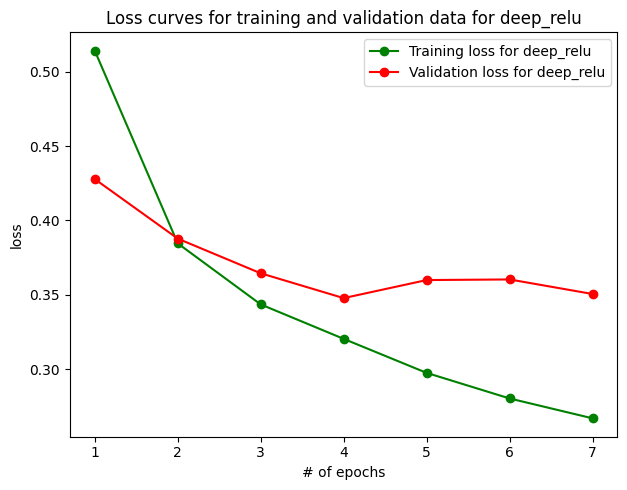

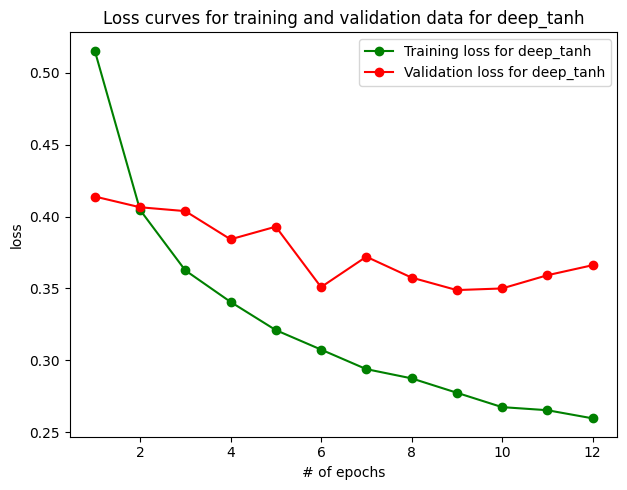

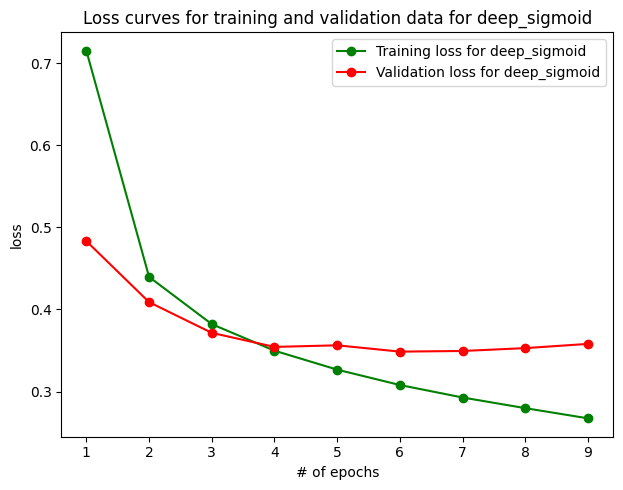

In [ ]:
for model, history in deep_histories.items():
  training_loss = history.history["loss"]
  validation_loss = history.history["val_loss"]
  epochs = range(1, len(training_loss) + 1)

  plt.figure(figsize = (12, 5))
  plt.subplot(1, 2, 1)
  plt.plot(epochs, training_loss, "go-", label = f"Training loss for {model}")
  plt.plot(epochs, validation_loss, "ro-", label = f"Validation loss for {model}")
  plt.title(f"Loss curves for training and validation data for {model}")
  plt.xlabel("# of epochs")
  plt.ylabel("loss")
  plt.legend()

  plt.tight_layout()
  plt.show()


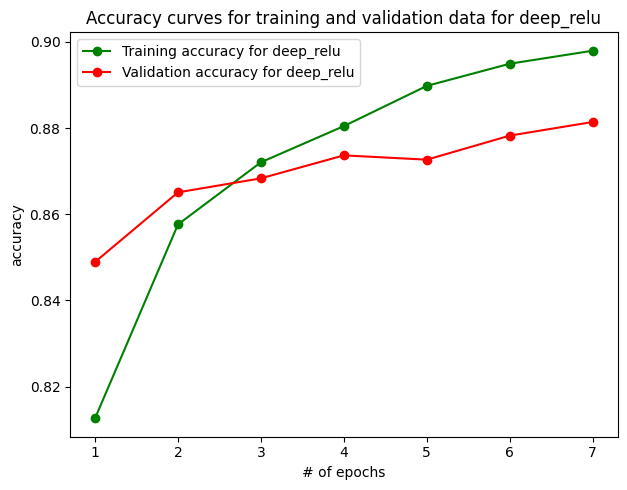

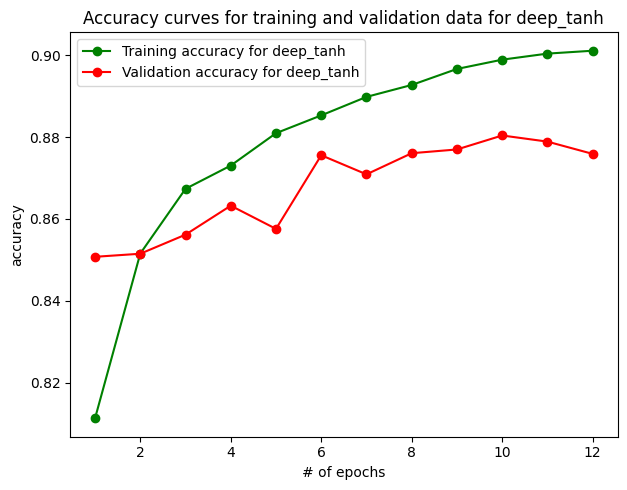

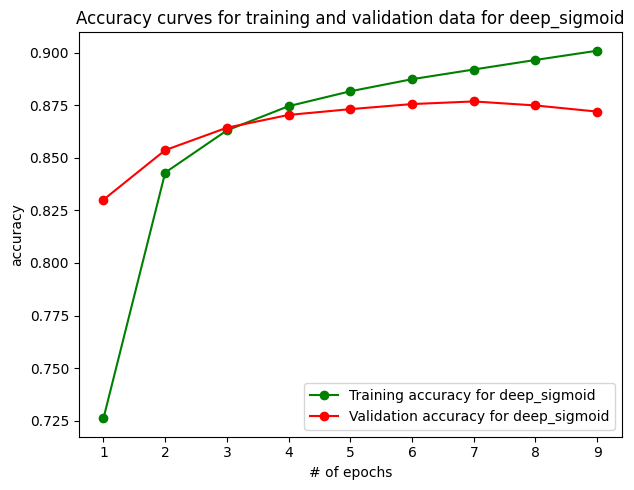

In [ ]:
for model, history in deep_histories.items():
  training_accuracy = history.history["accuracy"]
  validation_accuracy = history.history["val_accuracy"]
  epochs = range(1, len(training_accuracy) + 1)

  plt.figure(figsize = (12, 5))
  plt.subplot(1, 2, 1)
  plt.plot(epochs, training_accuracy, "go-", label = f"Training accuracy for {model}")
  plt.plot(epochs, validation_accuracy, "ro-", label = f"Validation accuracy for {model}")
  plt.title(f"Accuracy curves for training and validation data for {model}")
  plt.xlabel("# of epochs")
  plt.ylabel("accuracy")
  plt.legend()

  plt.tight_layout()
  plt.show()

# Deep Models

Confusion Matrices and classification reports for deep models

Deep relu and deep tanh seemed to struggle with clasifying class 4. In addition, deep relu seemed to have the worst performance out of all model architectures, only recording 593 true positives of class 6, the lowest out of any model architecture.



313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step




classification report for deep_relu
              precision    recall  f1-score   support

           0     0.8359    0.8250    0.8304      1000
           1     0.9958    0.9430    0.9687      1000
           2     0.7226    0.8310    0.7730      1000
           3     0.8034    0.9360    0.8647      1000
           4     0.7844    0.7420    0.7626      1000
           5     0.9882    0.9250    0.9556      1000
           6     0.7422    0.5930    0.6593      1000
           7     0.8471    0.9920    0.9139      1000
           8     0.9709    0.9690    0.9700      1000
           9     0.9789    0.8820    0.9279      1000

    accuracy                         0.8638     10000
   macro avg     0.8669    0.8638    0.8626     10000
weighted avg     0.8669    0.8638    0.8626     10000

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step




classification report for deep_tanh
              precision    recall  f1-score   support

           0     0.8123 

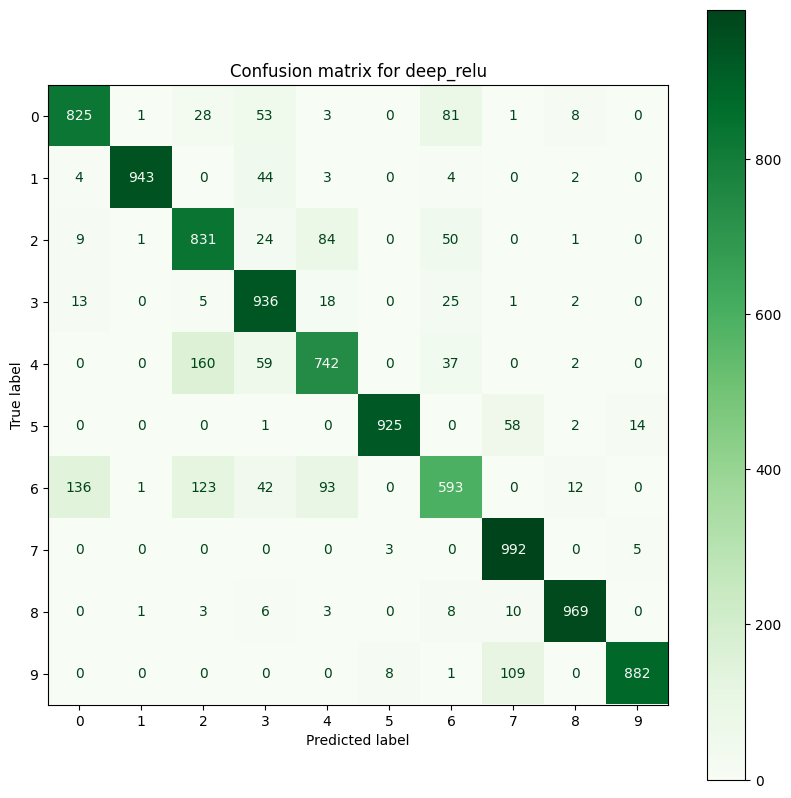

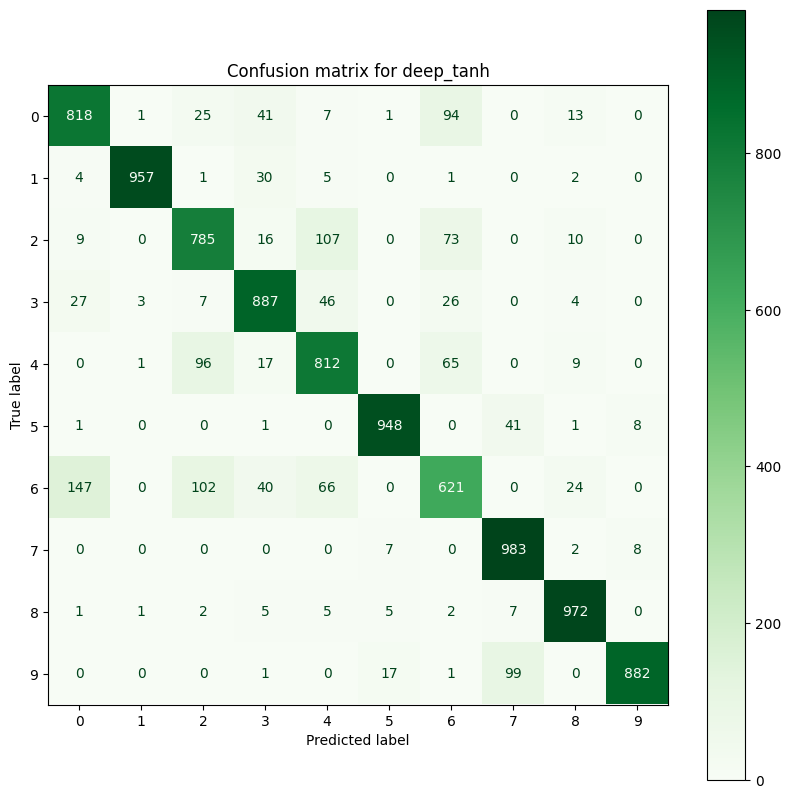

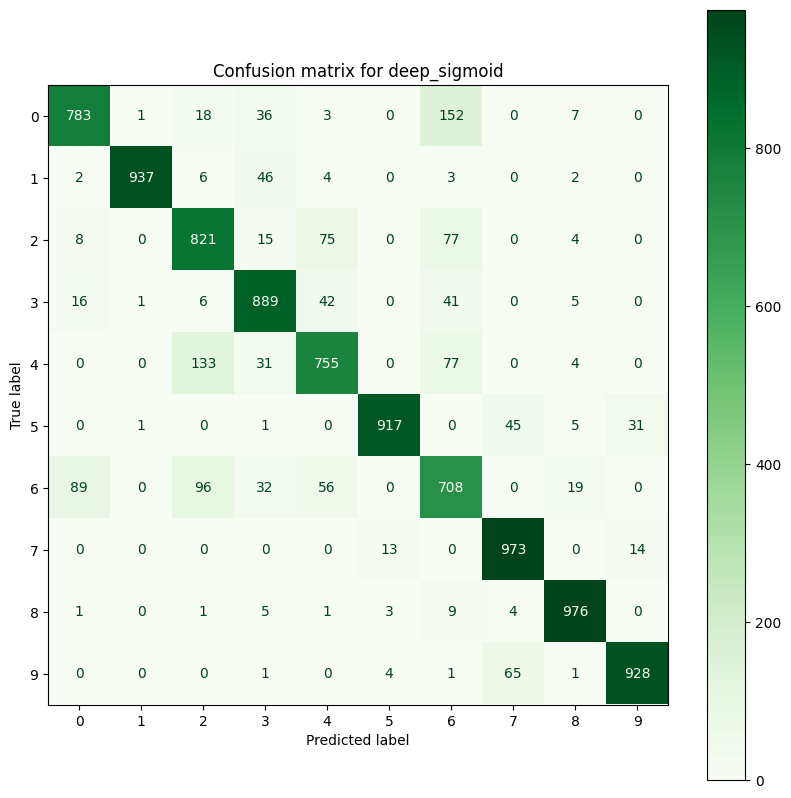

In [ ]:
for name, model in deep_models.items():
  y_pred = model.predict(X_test)
  y_pred_classes = np.argmax(y_pred, axis = 1)

  conf_matrix = confusion_matrix(y_test, y_pred_classes)
  fig, ax = plt.subplots(figsize = (10, 10))
  display = ConfusionMatrixDisplay(confusion_matrix = conf_matrix, display_labels = range(10))
  display.plot(ax = ax, values_format = "d", cmap=plt.cm.Greens)
  plt.title(f"Confusion matrix for {name}")
  print("\n")
  print("\n")
  class_report = classification_report(y_test, y_pred_classes, digits = 4)
  print(f"classification report for {name}")
  print(class_report)

#Summary table comparing shallow and deep models

First I created a list before iterating over both shallow and deep dictionaries, storing the loss and accuracy from the testing data, and displaying it by converting it from a list to a dataframe.

In [ ]:
summary = []

for name, model in shallow_models.items():
  loss, accuracy = model.evaluate(X_test, y_test, verbose = 0)
  split_model_functionality = name.split("_")
  model_architecture = split_model_functionality[0]
  activation_function = split_model_functionality[1]
  summary.append(
      {
          "model name": name,
          "architecture template": model_architecture,
          "activation function": activation_function,
          "model final test accuracy": round(accuracy, 3),
          "model final test loss": round(loss, 3)
      }
  )

for name, model in deep_models.items():
  loss, accuracy = model.evaluate(X_test, y_test, verbose = 0)
  split_model_functionality = name.split("_")
  model_architecture = split_model_functionality[0]
  activation_function = split_model_functionality[1]
  summary.append(
      {
          "model name": name,
          "architecture template": model_architecture,
          "activation function": activation_function,
          "model final test accuracy": round(accuracy, 3),
          "model final test loss": round(loss, 3)
      }
  )


summary_df = pd.DataFrame(summary, columns = ["model name", "architecture template", "activation function", "model final test accuracy", "model final test loss"])
summary_df

,model name,architecture template,activation function,model final test accuracy,model final test loss
0,shallow_relu,shallow,relu,0.867,0.372
1,shallow_tanh,shallow,tanh,0.862,0.373
2,shallow_sigmoid,shallow,sigmoid,0.870,0.366
3,deep_relu,deep,relu,0.864,0.374
4,deep_tanh,deep,tanh,0.867,0.379
5,deep_sigmoid,deep,sigmoid,0.869,0.377


**# Reflection**

**Which architecture template with a specific activation function performed better? Why?**

The shallow and deep architecture templates seemed to perform relatively the same, which was suprising as I had expected that deep learning models with more layers and neurons would have generalized each image category  more accurately compared to a shallow model with less neurons and layers would.

The shallow  sigmoid model seemed to perform the best out of all 6 models, with a test accuracy of 0.87 and a loss of 0.366. The deep variant of the sigmoid model also had a accuracy of 0.869 and a loss of 0.377.

Looking at the loss curves, we can see that the shallow sigmoid model had it's validation loss steadily decrease through epochs 1-7 before plateauing from epoch 8 and onward, while the training loss continued to decrease throughout all 15 epochs.  

In comparison, both shallow relu and shallow tanh models had significantly less total epochs  and had a increase in validation loss towards the end of training.

**What did the evaluation metrics tell you that accuracy did not?**

Looking at the classification report, we can see that across models that utilized shallow architecture, all 3 seemed to struggle in particular with class 6.

For example, the shallow sigmoid model had a recall of
95.6 and a f1-score of 97.35, but had a recall of 67.0 and f1-score of 67.37, which was not evident from looking at the loss or accuracy curves alone. This pattern was also evident for the shallow tanh and shallow relu model as well.

**How would you improve your models?**
Changing the architecture alone wouldnt necessarily improve the performance of the model, as we saw that deeper models resulted in nearly identical, if not worse results. Therefore, ways of improving the model's performance could include things such as changing the number of neurons within each hidden layer to observe how its metrics such as accuracy or loss improve or decrease based on its current parameters  instead of unnecessarily introducing more leayers.

**What are some potential ethical risks or limitations of using deep learning for image classification tasks like this one?**

Image misclassification and hallucination are risks especially as we saw in the example of the models performing much worse in accuracy and recall for class 6 compared to other classes. As we learned last year, marginalized groups or under-represented populations are at the highest risk of systems  directly as a result of systemic bias. If we were to deploy image classification systems that utilize deep learning for high stakes applications, such as immigration enforcement with little to no human oversight, serious concerns could be raised about how reliable the model truly is, particularly with the risk of mis-identifying individuals.